# StatArb Long-Short no S&P 500 — Pipeline Explicado Passo a Passo

**Projeto:** Desafio Itaú Asset Quant AI 2026
**Estratégia:** arbitragem estatística *long-short*, book de **$1 bi dollar-neutral**
(~$500mm por perna), **neutra aos fatores FF5+Momentum**, otimização convexa (cvxpy),
custos de execução **Almgren-Chriss**, hedge de beta residual com **SPY**.
**Sinal oficial:** **reversão de resíduo com z-score temporal** (`resid_ou`,
Avellaneda & Lee 2010) — escolhido por **evidência** no funil de pesquisa (seção 4.4).

Este notebook percorre o pipeline completo **usando o código de produção** (`statarb/`)
sobre os **dados reais** do S&P 500 com composição histórica correta. Cada seção
explica o *porquê* antes do *como*, no espírito do `alpha_signal_research_tutorial`.

**O mapa do pipeline** (a ordem das seções segue as dependências):

```
 (1) DADOS: S&P 500 as-of            quem existia e era negociável em cada dia
        |
 (2) MODELO DE FATORES               separa retorno em fatores + resíduo
        |--> resíduos    --> matéria-prima do SINAL (3)
        |--> betas       --> restrições do OTIMIZADOR (5) e hedge SPY
        |--> vol idio    --> escala do sinal e termo de risco
        |
 (3) SINAL resid_ou                  retorno idiossincrático acumulado, normalizado
        |
 (4) VALIDAÇÃO DE PESQUISA           IC, quintis, splits — o sinal prevê?
        |
 (5) OTIMIZADOR + (6) CUSTOS         do score à carteira executável
        |
 (7) BACKTEST OFICIAL                resid_ou no S&P 500 as-of (dev+val; holdout trancado)
```

In [1]:
# Setup: raiz do projeto, pacote statarb e estilo de plotagem
import sys, pathlib, json
ROOT = pathlib.Path.cwd()
if not (ROOT / "statarb").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from statarb.config import load_config, path_of
from statarb.viz.style import apply_style, PALETTE

apply_style()          # convencoes do projeto: figsize (12,5), grid, sem spines
cfg = load_config()
G = float(cfg["book"]["gross_usd"])
P = cfg["signal_params"]["resid_ou"]
print(f"book: ${G/1e9:.0f} bi | sinal oficial: resid_ou "
      f"(acumulo J={P['accum_days']}d, janela z W={P['z_window']}d)")

book: $1 bi | sinal oficial: resid_ou (acumulo J=60d, janela z W=252d)


## 1. Os dados: S&P 500 com composição histórica *as-of*

### 1.1 Por que "as-of"? O viés de sobrevivência

Um backtest precisa usar, em cada data, **o índice como ele era naquele dia** — não a
lista de hoje. Isso é a composição **as-of** (*"as of [uma data]"* = como estava naquela
data). Sem ela, o universo vira uma lista de vencedores por construção: as empresas que
quebraram ou foram adquiridas somem da história — o **viés de sobrevivência**
(*survivorship bias*) — e o resultado fica artificialmente inflado.

Exemplo concreto: o **Silicon Valley Bank** estava no índice até quebrar em mar/2023.
Com a lista de hoje ele nunca aparece no backtest; com a composição as-of, ele entra
até 2023 e o colapso acontece — como aconteceria na vida real.

### 1.2 Fontes (todas gratuitas e verificáveis)

| Painel | Fonte |
|---|---|
| **Composição as-of** (2.712 datas de mudança, 1996→2026) | change log oficial da Wikipedia (dataset `fja05680/sp500`) |
| **Preços/volume** ajustados | yfinance |
| **Fatores FF5+Momentum** diários | biblioteca do Ken French |
| **SPY** (hedge de beta) | yfinance |

Tudo é gravado num **schema canônico** (parquets padronizados) — o pipeline lê qualquer
fonte que escreva esse schema, sem alterar uma linha de código a jusante.

### 1.3 O viés residual, quantificado

Membership as-of resolve o viés de **seleção**; resta o de **dados**: parte dos membros
que saíram do índice não tem preço no yfinance. Medimos essa cobertura mês a mês
(está no `meta.json`) — em vez de ignorar o viés, nós o **quantificamos**: entre os
**removidos** do índice na janela, **46%** têm preço vs **99%** dos sobreviventes
(`reports/delisted_coverage_sp500.md`). *(No Russell 2000 seria 18% vs 92% — foi por
isso que a estratégia migrou para o S&P 500; ver `considerações/`.)*

#### ⚠️ Nota sobre o "gap" no início do gráfico 1.3a

O trecho inicial baixo **não é falta de dados** — é o **warm-up do filtro de histórico**.
O universo exige **pelo menos 260 dias úteis de histórico** por ação (mínimo para estimar
betas e vol com confiança); como o painel começa em jan/2018, quase nada é elegível até
~fev/2019. Toda avaliação começa **depois** do warm-up (`backtest.start = 2020`).
O mesmo explica degraus ao longo da curva: quem entra no índice só vira "negociável"
260 dias úteis depois de ter preço.

painel: 684 membros historicos x 2113 dias (2018-01-02 a 2026-05-29)
cobertura media dos membros as-of: 91.7% (minima 83.8% em 2018-02-01)


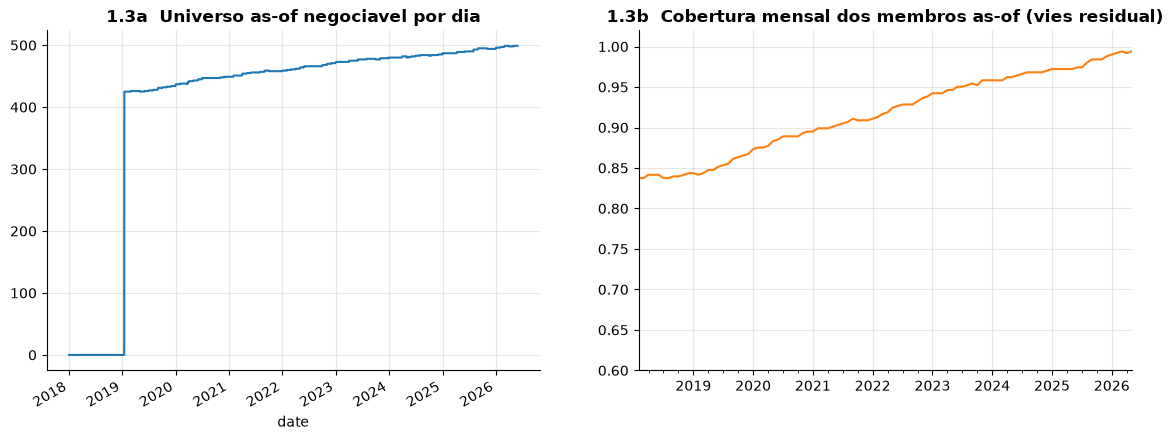

In [2]:
from statarb.data.loaders import MarketData
from statarb.data.universe import tradable_mask
from statarb.factors.betas import FactorModel

md_r = MarketData.from_dir(ROOT / "data" / "processed_sp500", cfg)
mask_r = tradable_mask(md_r, cfg)
meta = json.loads((ROOT / "data" / "processed_sp500" / "meta.json").read_text(encoding="utf-8"))
cov = meta["cobertura_membros_asof"]

print(f"painel: {md_r.returns.shape[1]} membros historicos x {md_r.returns.shape[0]} dias "
      f"({md_r.returns.index[0]:%Y-%m-%d} a {md_r.returns.index[-1]:%Y-%m-%d})")
print(f"cobertura media dos membros as-of: {cov['media']:.1%} "
      f"(minima {cov['minima']:.1%} em {cov['mes_minimo']})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mask_r.sum(axis=1).plot(ax=axes[0], color=PALETTE["strategy"])
axes[0].set_title("1.3a  Universo as-of negociavel por dia")
pd.Series({pd.Timestamp(k): v for k, v in cov["serie_mensal"].items()}).plot(ax=axes[1], color=PALETTE["cost"])
axes[1].set_title("1.3b  Cobertura mensal dos membros as-of (vies residual)")
axes[1].set_ylim(0.6, 1.02)
plt.show()

## 2. O modelo de fatores — a fundação de tudo

### 2.1 A decomposição: sistemático × idiossincrático

Todo retorno diário tem duas origens: a ação se moveu **com o grupo** (mercado caiu,
ações de valor subiram...) ou se moveu **sozinha** (notícia própria, fluxo de um fundo).
O modelo de fatores separa as duas:

$$ r_{i,t} = \underbrace{\beta_i' f_t}_{\textbf{sistemático}\;(\text{fatores})}
 + \underbrace{\varepsilon_{i,t}}_{\textbf{idiossincrático}\;(\text{resíduo})} $$

Os **fatores** $f_t$ são os 6 movimentos coletivos clássicos (Fama-French 5 +
Momentum): mercado, tamanho, valor, rentabilidade, investimento e momentum — séries
públicas do Ken French. O **resíduo** $\varepsilon$ é o que sobra: a "história própria"
da ação. **É nele que mora o alfa de arbitragem estatística.**

### 2.2 Como estimamos os betas

Para **cada ação**, uma regressão dos retornos diários dela sobre os retornos dos 6
fatores, em **janela móvel de 252 dias**, re-estimada a cada **21 dias** (betas mudam
devagar; re-estimar todo dia só adiciona ruído). **Anti-lookahead estrutural:** o
resíduo do dia *s* usa apenas betas estimados **antes** de *s*.

### 2.3 As três saídas e onde cada uma é usada

| Saída | Consumida por |
|---|---|
| **Resíduos** $\varepsilon$ | o sinal `resid_ou` (seção 3) — matéria-prima |
| **Betas** $\beta$ | otimizador (**neutralidade de fatores**) + hedge SPY |
| **Vol idiossincrática** | escala do sinal + termo de risco do otimizador |

89 datas de estimacao de betas


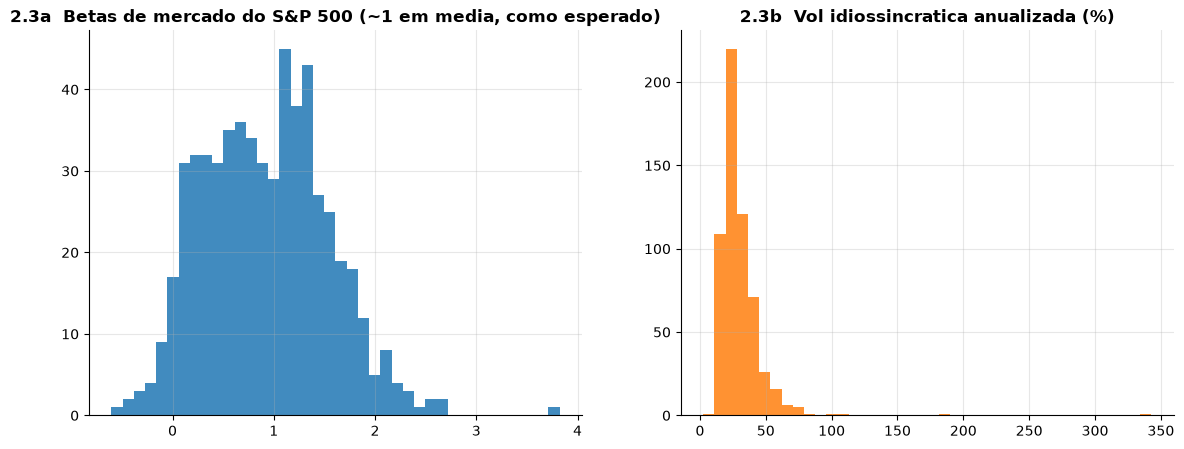

In [3]:
fm_r = FactorModel(cfg).fit(md_r.returns, md_r.factors)
B_last = fm_r.betas_asof(md_r.returns.index[-1])
ivol_last = fm_r.idio_asof(md_r.returns.index[-1])
print(f"{len(fm_r.est_index)} datas de estimacao de betas")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
B_last["mkt"].hist(bins=40, ax=axes[0], color=PALETTE["strategy"], alpha=0.85)
axes[0].set_title("2.3a  Betas de mercado do S&P 500 (~1 em media, como esperado)")
(ivol_last * np.sqrt(252) * 100).hist(bins=40, ax=axes[1], color=PALETTE["cost"], alpha=0.85)
axes[1].set_title("2.3b  Vol idiossincratica anualizada (%)")
plt.show()

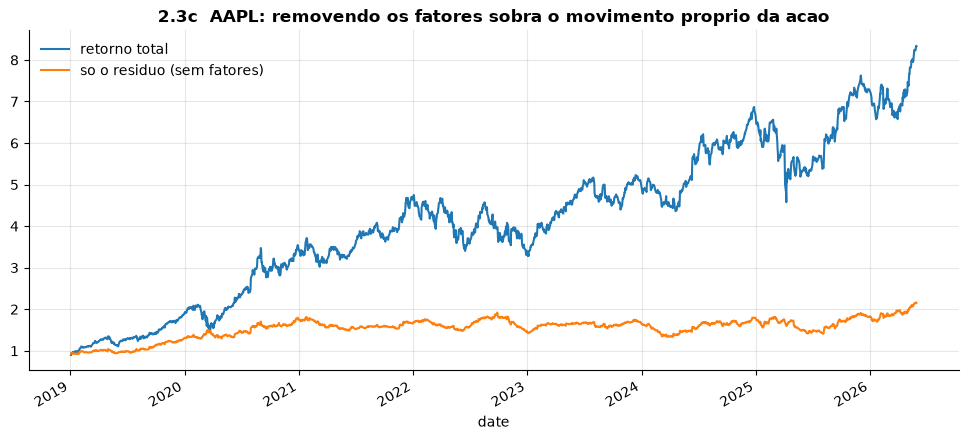

In [4]:
# O residuo em acao: um ticker real, retorno total vs so a "historia propria"
tk = "AAPL" if "AAPL" in md_r.returns.columns else md_r.returns.columns[0]
eps_r = fm_r.residuals[tk].dropna()
fig, ax = plt.subplots()
(1 + md_r.returns[tk].loc[eps_r.index]).cumprod().plot(ax=ax, label="retorno total", color=PALETTE["strategy"])
(1 + eps_r).cumprod().plot(ax=ax, label="so o residuo (sem fatores)", color=PALETTE["cost"])
ax.set_title(f"2.3c  {tk}: removendo os fatores sobra o movimento proprio da acao")
ax.legend(); plt.show()

## 3. O sinal oficial: `resid_ou` (reversão do retorno idiossincrático)

**De onde viemos:** a seção 2 nos deu, para cada ação e cada dia, o **resíduo** ε — o
retorno que os fatores *não* explicam. **O que fazemos agora:** transformar esses
resíduos no sinal de alfa que vai ordenar o universo.

Antes da matemática, vale fixar a anatomia de **qualquer** sinal de alfa. Ele tem três
camadas, e vamos construí-las nesta ordem:

1. **A tese** — a *crença econômica* sobre por que algo mensurável antecipa o desempenho futuro;
2. **A métrica** — o *número por ação* que traduz essa tese em algo calculável;
3. **O sinal** — a métrica *padronizada entre as ações*, pronta para ranquear o universo.

### 3.1 A tese

Tudo começa por uma crença (Avellaneda & Lee, 2010, *arbitragem estatística*):

> Quando uma ação acumula um **retorno idiossincrático** anormalmente grande — um
> movimento *próprio*, não explicado pelos fatores —, isso costuma ser **sobre-reação a
> fluxo** (liquidez, rebalanceamento de fundos), não informação nova. E sobre-reação
> **se desfaz**: esse movimento próprio tende a **reverter à média** no horizonte de ~1 mês.

A lógica do lucro é econômica: um vendedor apressado empurra o preço para longe do
equilíbrio; quem compra dele **provê liquidez** e é remunerado quando o preço volta.
Compramos o exagero para baixo e vendemos o exagero para cima.

*Por que ~1 mês?* Os dados (seção 4.4) mostram que a reversão **rápida de 5 dias morreu**
em large caps (arbitrada por HFT), mas a do horizonte **mensal sobrevive** — é essa que operamos.

### 3.2 A métrica

Para transformar a tese em número, precisamos medir *"quão esticado, e para qual lado,
está o movimento próprio desta ação"*. Isso se faz em dois passos.

**Passo 1 — Acumular o retorno idiossincrático:**

$$ X_i(t) = \sum_{k=0}^{J-1} \varepsilon_{i,\,t-k} \qquad (J = 60\text{ dias úteis}) $$

$X_i$ é o **retorno idiossincrático acumulado**: o quanto a ação andou *por conta
própria* nos últimos ~3 meses. Economicamente, é o **afastamento do equilíbrio de
fatores** que a tese diz que reverte. Resíduos de um único dia são ruído; somá-los revela
a tendência.

**Passo 2 — Comparar com o histórico da PRÓPRIA ação:**

$$ s_i(t) = -\,\frac{X_i(t) - \mu_i(t)}{\sigma_i(t)} $$

Aqui $\mu_i$ e $\sigma_i$ são a **média e o desvio-padrão móveis do próprio $X_i$**
(janela $W = 252$ dias). A pergunta respondida é: *"esse acúmulo é grande **para ESTA
ação**?"* — cada ação vira a sua própria régua, o que remove diferenças de escala (uma
biotech volátil vs. uma utility calma). O sinal de menos **inverte** o resultado: acúmulo
muito **acima** do normal dela → esticada para cima → "cara" → candidata a **short**;
muito **abaixo** → "barata" → **long**.

Esse $s_i$ é a **métrica**: um número por ação que já mede o esticamento relativo — mas
ainda na escala individual de cada uma.

### 3.3 O sinal

Falta um passo para a métrica virar sinal: torná-la **comparável entre as ações**.

**Passo 3 — Padronizar no corte transversal (todo dia):** os $s_i$ de todas as ações do
dia são transformados num **z-score cross-sectional** (média 0, desvio-padrão 1) e
**winsorizados** em ±3 (nenhum outlier domina o book).

**O resultado é o sinal `resid_ou`:** um número por ação, por dia, entre −3 e +3.
Positivo = retorno idiossincrático esticado para *baixo* → espera-se a volta para cima →
**compra**; negativo → **venda**. É esse vetor que alimenta o otimizador (seção 5).

> **Métrica × sinal — a distinção que importa:** a *métrica* ($s_i$, passos 1–2) mede o
> esticamento de cada ação contra **ela mesma**; o *sinal* (passo 3) coloca todas na
> **mesma régua** para dizer *quem está mais esticado que quem hoje*. Um book long-short
> ganha com o **ranking relativo**, não com o nível absoluto — por isso o passo 3 é
> indispensável.

### 3.4 Anti-lookahead

Por construção, todos os passos usam apenas janelas **para trás** (rolling) e resíduos
calculados com betas **passados**. Um teste automatizado
(`test_signal_no_lookahead[resid_ou]`) confirma: o sinal na data *t* é idêntico com ou
sem o futuro no painel.

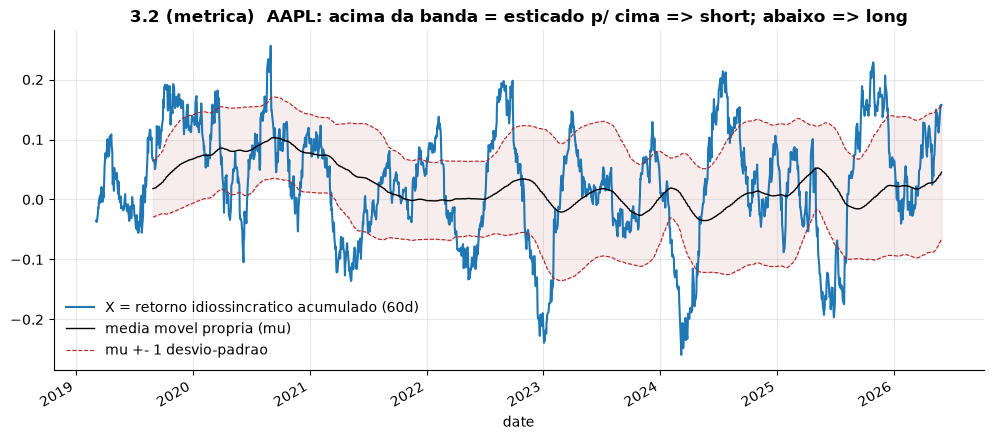

In [5]:
# Passos 1 e 2 visiveis em UMA acao: X acumulado vs bandas do proprio historico
from statarb.signals import build_signal

J, W = int(P["accum_days"]), int(P["z_window"])
X = fm_r.residuals[tk].rolling(J, min_periods=int(J * 0.7)).sum()
mu = X.rolling(W, min_periods=W // 2).mean()
sd = X.rolling(W, min_periods=W // 2).std()

fig, ax = plt.subplots()
X.plot(ax=ax, color=PALETTE["strategy"], label=f"X = retorno idiossincratico acumulado ({J}d)")
mu.plot(ax=ax, color="k", lw=1, label="media movel propria (mu)")
(mu + sd).plot(ax=ax, color=PALETTE["drawdown"], ls="--", lw=0.8, label="mu +- 1 desvio-padrao")
(mu - sd).plot(ax=ax, color=PALETTE["drawdown"], ls="--", lw=0.8, label="_")
ax.fill_between(X.index, mu - sd, mu + sd, alpha=0.08, color=PALETTE["drawdown"])
ax.set_title(f"3.2 (metrica)  {tk}: acima da banda = esticado p/ cima => short; abaixo => long")
ax.legend(); plt.show()

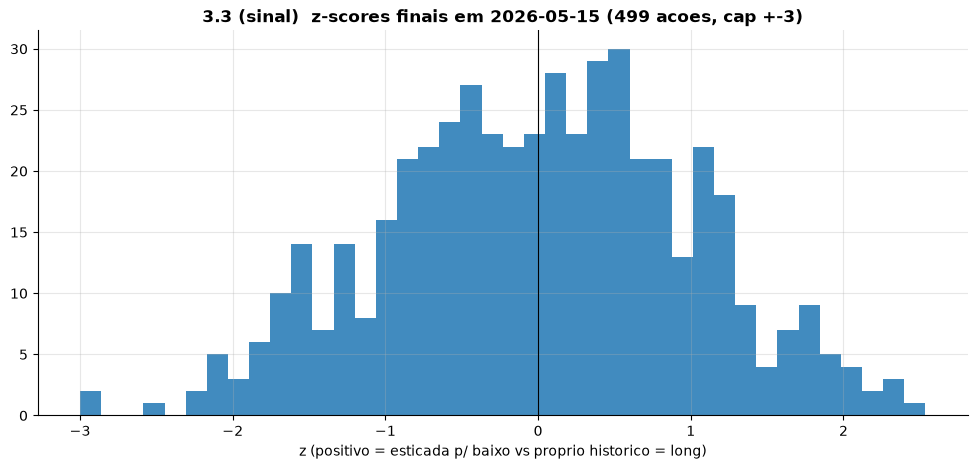

5 mais 'baratas' (long):  APH, GE, RTX, ZTS, HUBB
5 mais 'caras'  (short): CSCO, PANW, QCOM, ESS, CBOE


In [6]:
# Passo 3: o corte transversal em um dia -- z-scores prontos para o otimizador
sig = build_signal(cfg, "resid_ou")
d = md_r.returns.index[-10]
univ = list(mask_r.columns[mask_r.loc[d]])
z = sig.compute(md_r, fm_r, d, univ)

fig, ax = plt.subplots()
z.hist(bins=40, ax=ax, color=PALETTE["strategy"], alpha=0.85)
ax.axvline(0, color="k", lw=0.8)
ax.set_title(f"3.3 (sinal)  z-scores finais em {d:%Y-%m-%d} ({len(z)} acoes, cap +-3)")
ax.set_xlabel("z (positivo = esticada p/ baixo vs proprio historico = long)")
plt.show()

print("5 mais 'baratas' (long): ", ", ".join(z.nlargest(5).index))
print("5 mais 'caras'  (short):", ", ".join(z.nsmallest(5).index))

## 4. O sinal prevê? IC, quintis e o funil

### 4.1 Information Coefficient (IC)

**IC** = correlação (de postos, Spearman) entre o z-score de hoje e o **retorno residual
futuro**. Régua: IC de **0,03–0,05 já é bom** em ações — o lucro vem de acertar *pouco*
em *muitas* ações ao mesmo tempo (**Lei Fundamental de Grinold**: IR ≈ IC·√breadth).
Medimos contra o retorno **residual** (e não o total) porque a carteira é fator-neutra —
o que importa é prever o movimento idiossincrático.

### 4.2 Protocolo anti-overfitting

- **Execução defasada**: o score da data *t* é confrontado com o retorno de **t+2 em
  diante** (a posição só existiria a partir do fechamento de t+1 — sem lookahead);
- **Splits temporais**: **dev** (2020–22) e **validação** (2023) separados; o
  **holdout** (2024+) fica trancado para uma única ida final.

### 4.3 A escada de quintis

Ordenamos o universo pelo z-score e dividimos em 5 grupos: um sinal saudável mostra
**escada monotônica** — o quintil comprado rende mais que o vendido, com os do meio
no meio.

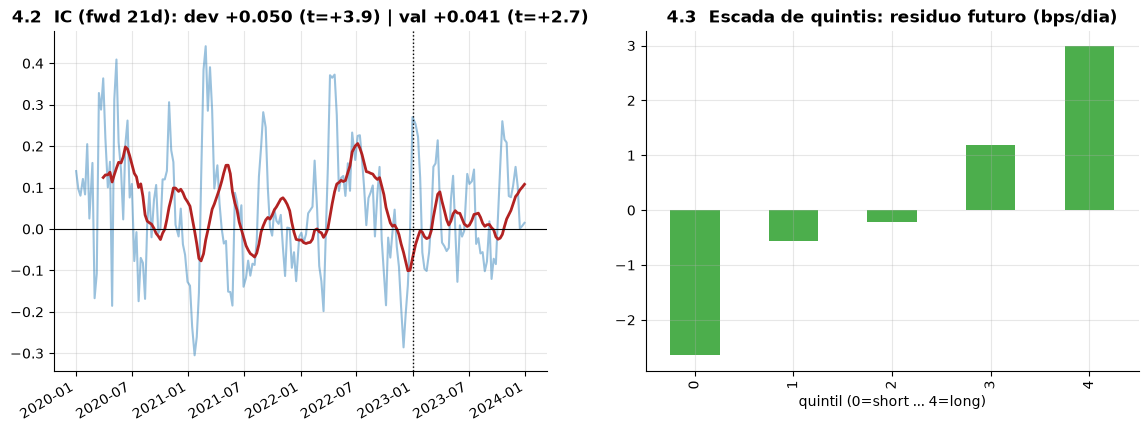

In [7]:
H = 21                                     # horizonte natural do sinal (~1 mes)
idx_r = md_r.returns.index
start_eval = idx_r.searchsorted(pd.Timestamp(cfg["backtest"]["start"]))
dev_end = pd.Timestamp(cfg["funnel"]["dev_end"]); val_end = pd.Timestamp(cfg["funnel"]["val_end"])

ics, qrets = [], []
for p in range(start_eval, len(idx_r) - H - 2, 5):
    d = idx_r[p]
    if d > val_end:                        # holdout trancado (protocolo)
        break
    univ_d = list(mask_r.columns[mask_r.loc[d]])
    z_d = sig.compute(md_r, fm_r, d, univ_d)
    if len(z_d) < 200:
        continue
    fwd = fm_r.residuals.iloc[p + 2 : p + 2 + H].sum(min_count=int(H * 0.7))
    common = z_d.index.intersection(fwd.dropna().index)
    ics.append((d, spearmanr(z_d[common], fwd[common])[0]))
    q = pd.qcut(z_d[common].rank(method="first"), 5, labels=False)
    qrets.append(fwd[common].groupby(q).mean())

ic = pd.Series(dict(ics))
quint = pd.concat(qrets, axis=1).mean(axis=1) * 1e4 / H

ic_dev, ic_val = ic[ic.index <= dev_end], ic[ic.index > dev_end]
t = lambda s: s.mean() / s.std() * np.sqrt(len(s))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ic.plot(ax=axes[0], color=PALETTE["strategy"], alpha=0.45)
ic.rolling(13).mean().plot(ax=axes[0], color=PALETTE["drawdown"], lw=2)
axes[0].axvline(dev_end, color="k", ls=":", lw=1); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title(f"4.2  IC (fwd {H}d): dev {ic_dev.mean():+.3f} (t={t(ic_dev):+.1f}) | "
                  f"val {ic_val.mean():+.3f} (t={t(ic_val):+.1f})")
quint.plot(kind="bar", ax=axes[1], color=PALETTE["iwm"], alpha=0.85)
axes[1].set_title("4.3  Escada de quintis: residuo futuro (bps/dia)")
axes[1].set_xlabel("quintil (0=short ... 4=long)")
plt.show()

### 4.4 Por que os outros sinais foram cortados (o funil)

Testamos **8 candidatos** da literatura no mesmo protocolo (`scripts/04_signal_funnel.py`;
resultados em `reports/funnel.md`). Resumo do veredito no S&P 500:

| Sinal | Resultado | Por quê |
|---|---|---|
| **resid_ou** | ✅ **único robusto** (IC21 t≈4 dev / t≈2 val) | reversão idiossincrática lenta sobrevive em large caps |
| reversão 5d | 🟡 fraca/inconsistente | arbitrada por HFT em large caps |
| trend, MAD, seasonality, left-tail | ❌ IC ≈ 0 | são em grande parte **proxies de fator** — a previsão deles mora nos fatores, que nós **neutralizamos** |
| STR-turnover | 🟡 fraco e redundante | primo do resid_ou; no **blend** não agregou nada (testado) |
| E/P | ⛔ sem EPS gratuito point-in-time | além de ser ~fator valor (seria neutralizado) |

**Lição de método:** num book fator-neutro, o funil mede o IC contra o retorno
*residual* — sinais que vivem de exposição a fator morrem **por construção**. O que
sobra é alfa idiossincrático puro. Um sinal robusto e bem entendido > um blend inflado
(o edital diz o mesmo: *estratégia simples bem executada supera complexa mal justificada*).

## 5. Do sinal ao portfólio: o otimizador convexo

O z-score vira **retorno esperado**: $\alpha_i = z_i \times$ (bps por unidade de z)
$\times$ (horizonte de ~21 dias — a posição rende até a reversão se completar, e esse
retorno acumulado compete com o **custo de entrada**, pago uma vez). A cada
rebalanceamento resolve-se:

$$ \max_w \;\; \alpha'w \;-\; \lambda\,(w'\Sigma w) \;-\; \text{custo}_{AC}(w - w_{prev}) $$

| Restrição | Significado |
|---|---|
| $\lvert\sum_i w_i\rvert \le 0{,}002$ | **dollar-neutral**: ~$500mm long, ~$500mm short |
| $\lVert w \rVert_1 \le 1$ | orçamento bruto de $1 bi |
| $\lvert B'w \rvert \le 0{,}02$ | **neutralidade a cada fator** — o retorno vem do resíduo, não de apostas em mercado/valor/momentum |
| $\lvert \sum_{i \in setor} w_i \rvert \le 5\%$ | **neutralidade setorial** — o resíduo FF não remove indústria; sem isso o book viraria aposta setorial disfarçada |
| $\lvert w_i \rvert \le \min(0{,}5\%,\, ADV_i/G)$ | concentração + liquidez |
| $\lvert \Delta w_i \rvert \le 5\%\, ADV_i/G$ | participação máxima no volume diário |

Tudo **convexo** → solução global única. A **covariância** entra na forma fatorada
$\Sigma = B F B' + D$ (nunca a matriz N×N — com N≈500 > T seria ruído). Um **portão de
viabilidade** rejeita soluções imprecisas do solver que violem o mandato. Após cada
rebalanceamento, o beta de mercado residual é zerado com **SPY** (dollar-neutral ≠
beta-neutral).

posicoes: 257 | gross: 1.000 do book | net: -0.00086
maior |net setorial|: 0.050 (limite 0.05) -- neutralidade setorial OK


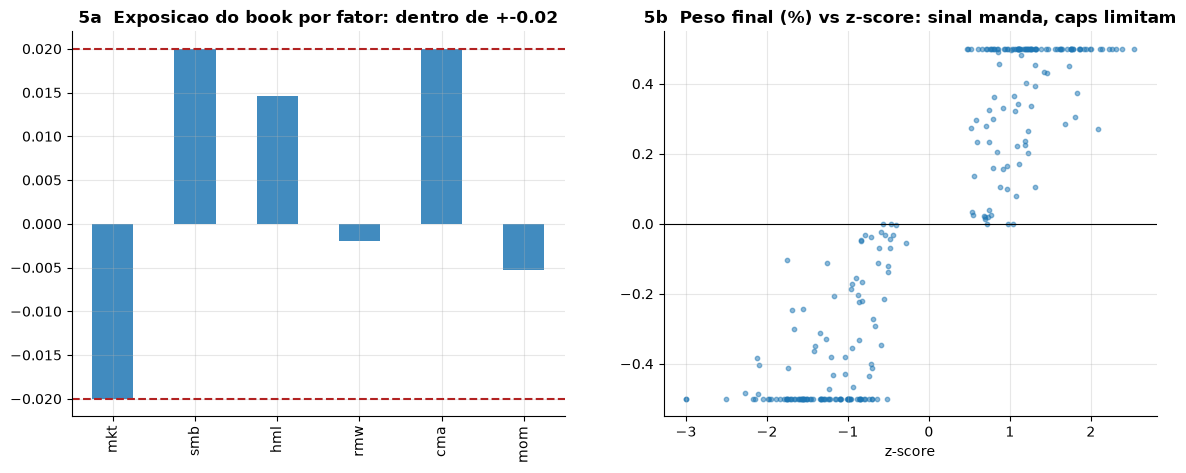

In [8]:
from statarb.costs.almgren_chriss import ACCostModel
from statarb.portfolio.optimizer import optimize_weights, to_series
from statarb.risk.covariance import factor_cov_chol, total_vol

B_df, ivol_s = fm_r.betas_asof(d), fm_r.idio_asof(d)
names = sorted(set(z.index) & set(B_df.index) & set(ivol_s.index))
adv_row = md_r.adv.loc[d].reindex(names)
names = [n for n, ok in zip(names, adv_row.notna().values) if ok]

alpha = z.reindex(names).values * 5e-4 * 21     # 5 bps/z ao dia, amortizado em ~21d
B = B_df.reindex(names).values
ivol = ivol_s.reindex(names).values
F_chol = factor_cov_chol(md_r.factors, d, 252)
sigma = total_vol(B, F_chol, ivol)
adv = md_r.adv.loc[d].reindex(names).values

sectors_d = md_r.sectors.reindex(names).fillna("Unknown").values
w = optimize_weights(alpha=alpha, B=B, F_chol=F_chol, ivol=ivol, sigma_total=sigma,
                     adv=adv, w_prev=np.zeros(len(names)),
                     cost_model=ACCostModel(cfg), cfg=cfg, sectors=sectors_d)
ws = to_series(w, names)
sec_net = pd.Series(w, index=names).groupby(pd.Series(sectors_d, index=names)).sum()
print(f"posicoes: {(ws != 0).sum()} | gross: {ws.abs().sum():.3f} do book | net: {ws.sum():+.5f}")
print(f"maior |net setorial|: {sec_net.abs().max():.3f} (limite 0.05) -- neutralidade setorial OK")

expo = pd.Series(B.T @ w, index=list(md_r.factors.columns))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
expo.plot(kind="bar", ax=axes[0], color=PALETTE["strategy"], alpha=0.85)
axes[0].axhline(0.02, color=PALETTE["drawdown"], ls="--"); axes[0].axhline(-0.02, color=PALETTE["drawdown"], ls="--")
axes[0].set_title("5a  Exposicao do book por fator: dentro de +-0.02")
axes[1].scatter(z.reindex(ws.index), ws * 100, s=10, alpha=0.5, color=PALETTE["strategy"])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("5b  Peso final (%) vs z-score: sinal manda, caps limitam")
axes[1].set_xlabel("z-score")
plt.show()

## 6. Custos de execução e convenção temporal

**Almgren-Chriss:** negociar $Q num papel com volume diário $ADV$ custa
*spread* + **impacto temporário** ($\propto\sigma\sqrt{Q/ADV}$, a "lei da raiz") +
**impacto permanente**. O MESMO modelo entra como penalidade no otimizador e como débito
no backtest — a carteira nasce ciente do próprio *footprint*.

**Convenção anti-lookahead do backtest** (quando formos rodá-lo):

```
close t   : sinal (dados <= t) -> otimizador -> pesos-alvo
close t+1 : execucao MOC + custos debitados
t+1 -> t+2: nova posicao comeca a render
```

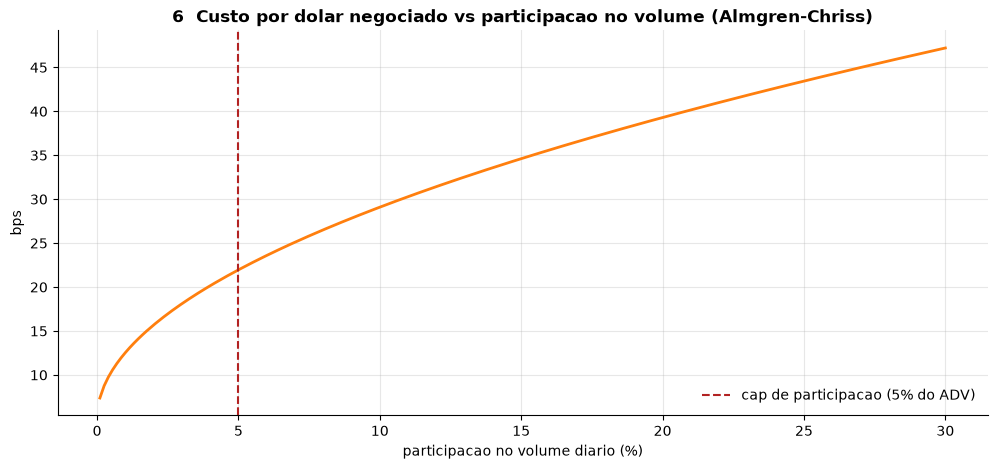

In [9]:
part = np.linspace(0.001, 0.30, 200)
sigma_d = 0.015
eta, gamma, spread = (float(cfg["costs"]["ac_eta"]), float(cfg["costs"]["ac_gamma"]),
                      float(cfg["costs"]["spread_bps"]))
bps = spread + 1e4 * (eta * sigma_d * np.sqrt(part) + 0.5 * gamma * sigma_d * part)

fig, ax = plt.subplots()
ax.plot(part * 100, bps, color=PALETTE["cost"], lw=2)
ax.axvline(5, color=PALETTE["drawdown"], ls="--", label="cap de participacao (5% do ADV)")
ax.set_title("6  Custo por dolar negociado vs participacao no volume (Almgren-Chriss)")
ax.set_xlabel("participacao no volume diario (%)"); ax.set_ylabel("bps"); ax.legend()
plt.show()

## 7. O backtest oficial: `resid_ou` no S&P 500 as-of (dev+val)

**De onde viemos:** sinal validado em pesquisa (IC, seção 4) e carteira bem definida
(otimizador + custos, seções 5–6). **O que fazemos aqui:** a simulação completa e
oficial — sinal → otimizador (com TODAS as restrições, inclusive a **setorial**) →
custos Almgren-Chriss → execução t+1 → hedge SPY → P&L dia a dia.

**Janela: 2020 → 2023 (dev+validação). O holdout (2024+) permanece TRANCADO** — será
usado uma única vez, na decisão final (protocolo anti-overfitting).

*Os resultados abaixo são lidos de `reports/sp500_dev_val/` (gerados por
`scripts/02_run_backtest.py --data processed_sp500 --bt-end 2023-12-31 --tag sp500_dev_val`).*

In [10]:
import json as _json
REP = ROOT / "reports" / "sp500_dev_val"
res_bt = pd.read_parquet(REP / "results_daily.parquet")
m_bt = _json.loads((REP / "metrics.json").read_text(encoding="utf-8"))

resumo = pd.Series({
    "Sharpe bruto": m_bt["sharpe_gross"], "Sharpe liquido": m_bt["sharpe_net"],
    "Retorno liquido (% a.a. do gross)": m_bt["ann_return_net_pct"],
    "Vol (% a.a.)": m_bt["ann_vol_pct"], "Max drawdown (%)": m_bt["max_drawdown_pct"],
    "Turnover (x gross/ano)": m_bt["ann_turnover_x"],
    "Custos (bps do gross/ano)": m_bt["costs_bps_of_gross_per_year"],
    "Gross medio": m_bt["avg_gross"], "|Net| maximo": m_bt["max_abs_net"],
    "Max |expo fator|": m_bt["max_abs_factor_expo"],
    "Max |net setorial|": float(res_bt["max_sector_net"].max()) if "max_sector_net" in res_bt else float("nan"),
    "Posicoes (media)": m_bt["avg_n_positions"],
    "P&L liquido acumulado (USD mm)": m_bt["pnl_net_total_usd_mm"],
}).round(3)
resumo.to_frame("valor")

,valor
Sharpe bruto,0.532
Sharpe liquido,0.198
Retorno liquido (% a.a. do gross),1.182
Vol (% a.a.),5.958
Max drawdown (%),-10.899
Turnover (x gross/ano),15.059
Custos (bps do gross/ano),198.271
Gross medio,0.999
|Net| maximo,0.002
Max |expo fator|,0.592


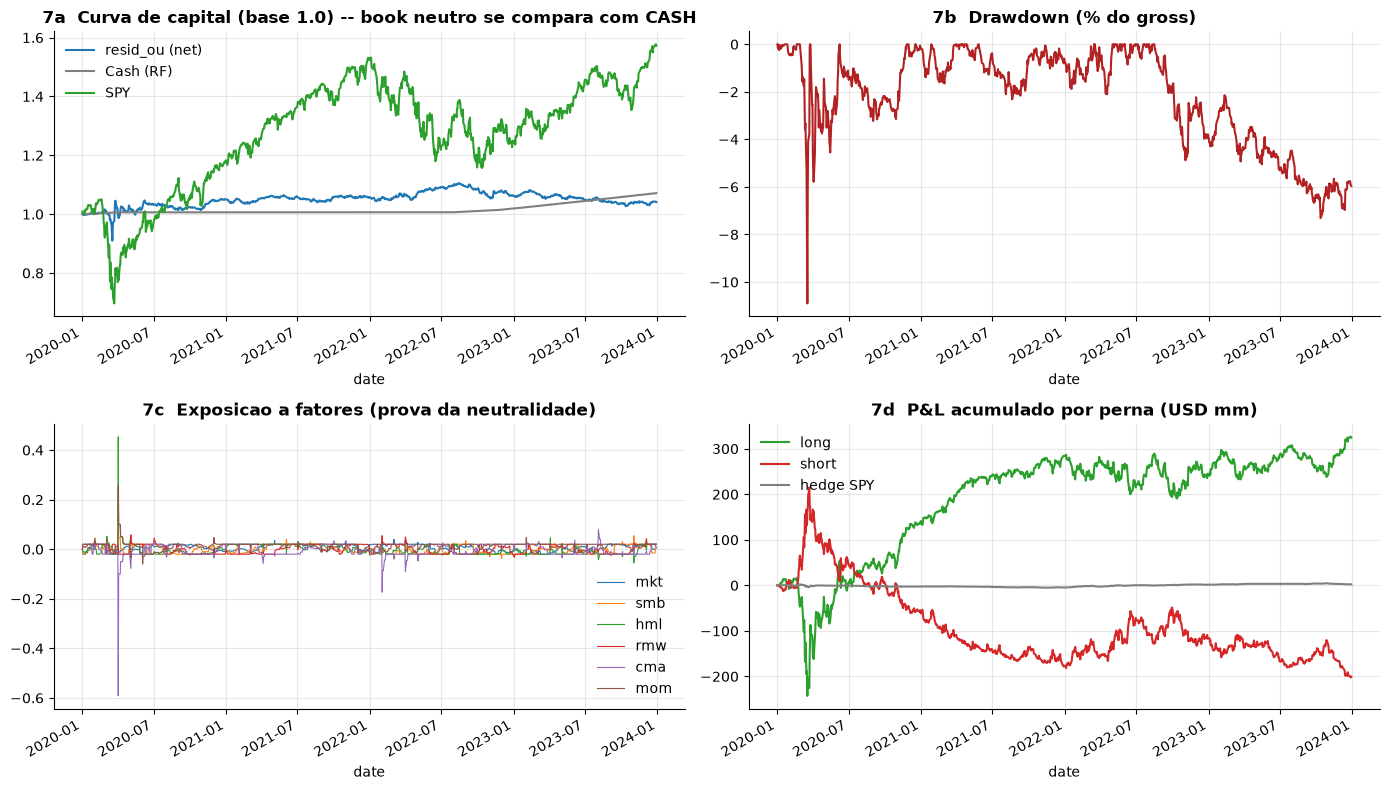

Por ano (ret liq % a.a. | Sharpe):
  2020:  +5.40%  |  +0.52
  2021:  +0.68%  |  +0.22
  2022:  +0.78%  |  +0.19
  2023:  -2.18%  |  -0.70


In [11]:
G_ = 1e9
eq_bt = pd.DataFrame({
    "resid_ou (net)": (1 + res_bt["pnl_net_usd"] / G_).cumprod(),
    "Cash (RF)": (1 + md_r.rf.reindex(res_bt.index).fillna(0)).cumprod(),
    "SPY": (1 + md_r.iwm_ret.reindex(res_bt.index).fillna(0)).cumprod(),
})
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
eq_bt.plot(ax=axes[0, 0], color=[PALETTE["strategy"], PALETTE["benchmark"], PALETTE["iwm"]])
axes[0, 0].set_title("7a  Curva de capital (base 1.0) -- book neutro se compara com CASH")

cum = res_bt["pnl_net_usd"].cumsum() / G_ * 100
(cum - cum.cummax()).plot(ax=axes[0, 1], color=PALETTE["drawdown"])
axes[0, 1].set_title("7b  Drawdown (% do gross)")

expo_cols = [c for c in res_bt.columns if c.startswith("expo_")]
res_bt[expo_cols].rename(columns=lambda c: c[5:]).plot(ax=axes[1, 0], lw=0.8)
axes[1, 0].set_title("7c  Exposicao a fatores (prova da neutralidade)")

(res_bt[["pnl_long_usd", "pnl_short_usd", "pnl_hedge_usd"]].cumsum() / 1e6).rename(
    columns={"pnl_long_usd": "long", "pnl_short_usd": "short", "pnl_hedge_usd": "hedge SPY"}
).plot(ax=axes[1, 1], color=[PALETTE["long"], PALETTE["short"], PALETTE["benchmark"]])
axes[1, 1].set_title("7d  P&L acumulado por perna (USD mm)")
plt.tight_layout(); plt.show()

daily_net = res_bt["pnl_net_usd"] / G_
by_year = daily_net.groupby(res_bt.index.year).apply(lambda x: (x.mean()*252*100, x.mean()/x.std()*np.sqrt(252)))
print("Por ano (ret liq % a.a. | Sharpe):")
for y, (r_, s_) in by_year.items():
    print(f"  {y}: {r_:+6.2f}%  |  {s_:+.2f}")

## 8. Estado, próximos passos e glossário

### 8.1 O que já está validado

1. **Pipeline**: recuperou alfa plantado em painel sintético (gabarito), P&L verificado
   contra a biblioteca `bt` (corr 0,996), 14 testes automáticos (anti-lookahead de 9
   sinais, neutralidade + setor, custos convexos);
2. **Dados**: S&P 500 as-of com viés de seleção resolvido e viés de dados quantificado
   (92% membros; removidos 46% vs 99% sobreviventes);
3. **Sinal**: `resid_ou` escolhido por evidência (11 candidatos testados no total;
   blend descartado duas vezes por não agregar);
4. **Backtest oficial dev+val** rodado com mandato completo (seção 7).

### 8.2 Próximos passos

1. **Análise crítica** dos resultados (custos, capacidade, crises 2020/2022);
2. **Ida única ao holdout** (2024+) — o número final da estratégia;
3. **Relatório de 5 páginas + robô** (prazos: pré-relatório 31/07, final 17/08).

### 8.3 Glossário

| Termo | Significado |
|---|---|
| **Alfa** | retorno que vem de *prever*, não de carregar risco de mercado |
| **Fator / beta** | movimento coletivo (mercado, valor, momentum...) / sensibilidade a ele |
| **Resíduo (idiossincrático)** | o pedaço do retorno que os fatores não explicam |
| **Composição as-of** | o índice como era em cada data (mata o viés de sobrevivência) |
| **Reversão à média** | tendência de valores esticados voltarem ao nível normal |
| **Retorno idiossincrático acumulado** | soma dos resíduos numa janela; o quanto a ação andou "por conta própria" |
| **Métrica × sinal** | métrica = número por ação (contra si mesma); sinal = métrica padronizada entre as ações |
| **z-score temporal** | medida padronizada de uma ação contra o próprio histórico |
| **z-score cross-sectional** | padronização entre ações no mesmo dia (média 0, dp 1) |
| **IC** | correlação sinal → retorno futuro; 0,03–0,05 já é bom |
| **Dev / validação / holdout** | janelas separadas p/ evitar overfitting; holdout = uma ida |
| **Dollar-neutral / fator-neutro** | $long=$short / exposição ~0 a cada fator |
| **ADV / turnover / gross / net** | volume médio diário / giro / soma \|posições\| / líquido |
| **Almgren-Chriss** | modelo de custo: spread + impacto temporário (√) + permanente |